# Which Rival Weakness Should Our New Cozy Game Turn Into Its Strength?
**MADT 7202 · Mid-Term Applied Case** · A game × complaint network from Steam negative reviews of 15 rival cozy indie games

**The decision.** A small indie studio is about to build a new cozy game. Before pre-production, the head of studio must pick **one thing the game will do better than its rivals**. Most of the time and budget will go there.

**The idea in one line.** Read what players complain about in rival cozy games, and find the complaint that shows up in the **most different games**. That is a weakness of the whole market, so it is the best one to turn into our strength.

**Why a network, not a table.** A table shows which complaint is the *loudest* (most reviews). But a loud complaint can come from one big game. That is that game's problem, not the market's. We need to know how many *different* rivals share each complaint, which is a link pattern between games and complaints:

- 🟠 **game** nodes: 15 rival cozy indie games
- 🔵 **complaint** nodes: what players complain about (decoration, farming, story, progression…)
- **line** = players complain about that topic in that game
- the answer = the complaint node with the **most lines** (its *degree*, Chapter 7)

| Step | What happens |
|---|---|
| 1 | Pick the 15 most-reviewed paid cozy indie games on Steam (SteamSpy) |
| 2 | Download recent **negative** reviews in English and Thai (Steam store) |
| 3 | Find which topics each review complains about (word lists) |
| 4 | Remove complaints that every game gets: bugs, price, "too short / boring" |
| 5 | Draw a line when ≥ 10 % of a game's negative reviews complain about a topic (conditional weight, Ch 6) |
| 6 | Pick the topic linked to the most games, and compare with the loudest topic |
| 7 | Check the answer holds when the cutoffs change |

> For education only. Only public review text and dates are kept. No usernames, Steam IDs or other personal data.

## 0 · Setup
No API key is needed. Both sources are public.

In [ ]:
import os, json, time, math, random, re, shutil
from collections import Counter
from datetime import datetime, timezone
import requests
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

### Settings
The values used in the report. Numbers in brackets are the other values tried in the robustness check (section 7).

In [ ]:
SEED_TAG    = "Cozy"                  # how the rival games are chosen
N_GAMES     = 15                      # number of rival games
MIN_REVIEWS = 1000                    # each with at least 1,000 Steam reviews
LANGS       = ["english", "thai"]     # we have word lists for these two languages
N_PER_LANG  = 300                     # most recent negative reviews per game, per language

LINK_SHARE  = 0.10                    # line if ≥ 10 % of the game's negative reviews complain about it  (sweep: 5, 10, 15 %)
MIN_REVIEWS_PER_LINK = 5              # ...and at least 5 reviews                                         (sweep: 3, 5, 8)
SWEEP_SHARE = [0.05, 0.10, 0.15]
SWEEP_MIN   = [3, 5, 8]
N_BOOT      = 500

# Complaint topics. English patterns use word boundaries; Thai has no spaces between words, so Thai patterns are plain text.
TOPICS = {
    "Decoration":          [r"\bdecor\w*", r"\bfurniture", r"\bcustomi[sz]\w*", r"\binterior",
                            "ตกแต่ง", "แต่งบ้าน", "เฟอร์นิเจอร์", "ของแต่ง"],
    "Farming":             [r"\bfarm\w*", r"\bcrops?\b", r"\bharvest\w*", r"\bplant(?:s|ing)?\b", r"\bgarden\w*",
                            "ปลูก", "เก็บเกี่ยว", "พืช", "ทำฟาร์ม"],
    # story = the writing itself; bare "character" / "villager" / "NPC" are left out because they often mean the
    # player avatar, a 3D model or a UI button (found in the first hand audit)
    "Story & Characters":  [r"\bstor(?:y|ies|yline)\b", r"\bplot\b", r"\bnarrative", r"\bwriting\b", r"\blore\b",
                            r"\bdialog\w*", r"\bcharacters (?:are|were|feel|felt|lack|have no)\b",
                            r"\b(?:flat|boring|bland|shallow|forgettable|annoying|unlikable|one-dimensional) characters?\b",
                            "เนื้อเรื่อง", "เรื่องราว", "บทสนทนา"],
    "Exploration":         [r"\bexplor\w*", r"\bdiscover\w*", r"\bsecrets?\b", r"\bbiomes?\b", r"\bmap\b",
                            "สำรวจ", "แผนที่", "ความลับ"],
    "Crafting & Building": [r"\bcraft\w*", r"\bbuild(?:s|ing)?\b", r"\bconstruct\w*", "คราฟ", "ก่อสร้าง", "สร้างบ้าน"],
    "Cooking":             [r"\bcook\w*", r"\brecipes?\b", r"\bdish(?:es)?\b", r"\bkitchen", "ทำอาหาร", "สูตรอาหาร", "ครัว"],
    "Progression":         [r"\bprogress\w*", r"\bupgrad\w*", r"\bunlock\w*", r"\bend ?game\b", r"\bgrind\w*",
                            "อัพเกรด", "อัปเกรด", "ปลดล็อก", "เลเวล", "ฟาร์มของ"],
    "Co-op":               [r"\bco-?op\b", r"\bmultiplayer\b", r"\bwith (?:my )?friends?\b", r"\bsplit[- ]?screen",
                            "เล่นกับเพื่อน", "มัลติ", "โคออป"],
    # "cat"/"dog" are left out: in cat games they name the player character, not a feature;
    # "Animal Crossing" is a game title, not a complaint about animals
    "Animals & Pets":      [r"\banimals?\b(?! crossing)", r"\bpets?\b(?! door)", r"\bcreatures?\b", "สัตว์เลี้ยง"],
    "Fishing & Collecting":[r"\bfish\w*", r"\bcollect\w*", r"\bmuseum\b", "ตกปลา", "สะสม"],
    "Management":          [r"\bmanag\w*", r"\bcustomers?\b", r"\bshop\b", r"\bbusiness\b", r"\bstaff\b",
                            "บริหาร", "จัดการ", "ลูกค้า", "พนักงาน"],
}
# Complaints every game gets. Measured and reported, then removed before ranking (like "price" in the course sample).
GENERIC = {
    "Bugs & Performance": [r"\bbugs?\b", r"\bbuggy\b", r"\bcrash\w*", r"\bglitch\w*", r"\blag\w*", r"\bfps\b",
                           r"\bperformance\b", "บัค", "บั๊ก", "แครช", "เด้งออก", "กระตุก", "แลค"],
    "Price":              [r"\bprice\w*", r"\brefund\w*", r"\bexpensive\b", r"\bworth\b", "ราคา", "แพง", "คืนเงิน"],
    "Too short / Boring": [r"\bcontent\b", r"\bshort\b", r"\brepetitive\b", r"\bboring\b", r"\btedious\b",
                           "สั้น", "น่าเบื่อ", "ซ้ำซาก"],
    "Cozy words (seed)":  [r"\bco[sz]y\b", r"\brelax\w*", r"\bchill\w*", r"\bcute\b", "ผ่อนคลาย", "น่ารัก", "ชิล"],
}

RAW, OUT = "data/raw", "outputs"
os.makedirs(RAW, exist_ok=True); os.makedirs(OUT, exist_ok=True)
RUN_DATE = datetime.now(timezone.utc).strftime("%Y-%m-%d")
random.seed(42); np.random.seed(42)

SESSION = requests.Session()
SESSION.headers["User-Agent"] = "MADT7202-midterm-educational/1.0"

def get_json(url, params=None, tries=5, timeout=60):
    for i in range(tries):
        try:
            r = SESSION.get(url, params=params, timeout=timeout)
        except requests.RequestException:
            time.sleep(2 ** i); continue
        if r.status_code == 429 or r.status_code >= 500:
            time.sleep(5 * 2 ** i); continue
        r.raise_for_status()
        try:
            return r.json()
        except ValueError:
            time.sleep(2 ** i)
    return None

def cached(path, fetch):
    if os.path.exists(path):
        return json.load(open(path))
    data = fetch()
    if data is not None:
        json.dump(data, open(path, "w"))
    return data

## 1 · Collect: the 15 rival games
SteamSpy's public API lists every game tagged *Cozy*. We keep paid games with at least 1,000 reviews that are also tagged *Indie* and have *Cozy* among their top-15 player tags, and take the 15 with the most reviews. These are the games a new cozy indie game will be compared with.

In [ ]:
listing = cached(f"{RAW}/steamspy_tag_{SEED_TAG}.json",
                 lambda: get_json("https://steamspy.com/api.php", dict(request="tag", tag=SEED_TAG), timeout=180))
assert listing, "SteamSpy did not answer — wait a minute and re-run this cell"
cand = pd.DataFrame(listing.values())
cand["appid"] = cand.appid.astype(str)
for c in ["positive", "negative", "initialprice"]:
    cand[c] = pd.to_numeric(cand.get(c, 0), errors="coerce").fillna(0)
cand["reviews"] = cand.positive + cand.negative
cand = cand[(cand.appid != "999999") & (cand.initialprice > 0) & (cand.reviews >= MIN_REVIEWS)]
cand = cand.sort_values("reviews", ascending=False).head(60)

def tags_of(a):
    def go():
        time.sleep(1.0)
        return get_json("https://steamspy.com/api.php", dict(request="appdetails", appid=a))
    t = (cached(f"{RAW}/spy_{a}.json", go) or {}).get("tags") or {}
    return [k for k, _ in sorted(t.items(), key=lambda kv: -kv[1])] if isinstance(t, dict) else []

rows = []
for a, name, rev in tqdm(list(zip(cand.appid, cand.name, cand.reviews)), desc="tags"):
    t = tags_of(a)
    if "Indie" in t and SEED_TAG in t[:15]:
        rows.append(dict(appid=a, game=name, reviews=int(rev), top_tags="; ".join(t[:6])))
    if len(rows) == N_GAMES:
        break
games = pd.DataFrame(rows)
print(f"SteamSpy '{SEED_TAG}' list: {len(listing):,} games → {len(games)} rival cozy indie games")
games[["game", "reviews", "top_tags"]]

tags:   0%|          | 0/60 [00:00<?, ?it/s]

SteamSpy 'Cozy' list: 779 games → 15 rival cozy indie games


,game,reviews,top_tags
0,Tiny Glade,19845,Building; Design & Illustration; Relaxing; San...
1,A Little to the Left,13536,Puzzle; Relaxing; Wholesome; Casual; Cute; Cozy
2,"Little Kitty, Big City",10785,Cats; Cute; Wholesome; Exploration; Cozy; Fami...
3,Kind Words (lo fi chill beats to write to),8936,Emotional; Relaxing; Cozy; Wholesome; Multipla...
4,Cozy Grove,7998,Relaxing; Cute; Story Rich; Cozy; Collectathon...
5,Melatonin,7106,Rhythm; Indie; Cute; Hand-drawn; Colorful; Music
6,Alba: A Wildlife Adventure,6640,Casual; Wholesome; Cozy; Family Friendly; Natu...
7,Sticky Business,6171,Casual; Relaxing; Simulation; Cute; Indie; Who...
8,"Good Pizza, Great Pizza - Cooking Simulator Game",5719,Funny; Management; Time Management; Cooking; C...
9,Minami Lane,5307,Cute; Casual; Life Sim; Relaxing; Management; ...


## 2 · Collect: recent negative reviews (English + Thai)
For each game, the Steam store's public review feed gives up to 300 of the most recent **negative** reviews per language. Only the text, language and date are kept.

In [ ]:
def fetch_negative(appid, lang, n=N_PER_LANG):
    def go():
        out, seen, cursor = [], set(), "*"
        while len(out) < n:
            js = get_json(f"https://store.steampowered.com/appreviews/{appid}",
                          dict(json=1, filter="recent", language=lang, review_type="negative",
                               purchase_type="all", num_per_page=100, cursor=cursor))
            if not js or not js.get("success"):
                break
            new = [r for r in js.get("reviews", []) if r["recommendationid"] not in seen]
            if not new:
                break
            for r in new:
                seen.add(r["recommendationid"])
                out.append(dict(text=r.get("review", ""), ts=r["timestamp_created"]))
            cursor = js.get("cursor", cursor)
            time.sleep(1.0)
        return out[:n]
    return cached(f"{RAW}/neg_{appid}_{lang}.json", go)

recs = []
for a, g in tqdm(list(zip(games.appid, games.game)), desc="reviews"):
    for lang in LANGS:
        for r in fetch_negative(a, lang):
            recs.append(dict(game=g, lang=lang, text=r["text"], ts=r["ts"]))
reviews = pd.DataFrame(recs)
reviews = reviews[reviews.text.str.strip().str.len() > 0].reset_index(drop=True)
PERIOD = (datetime.fromtimestamp(reviews.ts.min(), timezone.utc).strftime("%Y-%m-%d"),
          datetime.fromtimestamp(reviews.ts.max(), timezone.utc).strftime("%Y-%m-%d"))
BY_LANG = reviews.lang.value_counts().to_dict()
print(f"{len(reviews):,} negative reviews · " + " · ".join(f"{k}: {v:,}" for k, v in BY_LANG.items()) +
      f" · {PERIOD[0]} → {PERIOD[1]}")
reviews.groupby(["game", "lang"]).size().unstack(fill_value=0)

reviews:   0%|          | 0/15 [00:00<?, ?it/s]

3,407 negative reviews · english: 3,400 · thai: 7 · 2019-09-14 → 2026-10-13


lang,english,thai
game,,
A Little to the Left,300,1
Alba: A Wildlife Adventure,83,0
Cats Organized Neatly,63,0
Cozy Grove,300,0
"Good Pizza, Great Pizza - Cooking Simulator Game",300,0
Kind Words (lo fi chill beats to write to),147,0
LEGO Builder's Journey,300,0
Lil Gator Game,66,0
"Little Kitty, Big City",271,0


## 3 · Find what each review complains about
Each review is checked against the word lists. The lists were tightened after a first hand audit: bare "character", "villager", "NPC", "cat" and "dog" mostly named the player avatar, a 3D model or the game's own subject, and "Animal Crossing" is a game title. One review can complain about several topics. The whole review is the unit (each review belongs to exactly one game, so there is no word window to choose).

`outputs/audit_sample.csv` holds **100 random matches**. Mark each one y/n to measure how accurate the word lists are.

In [ ]:
PAT = {t: re.compile("|".join(p)) for t, p in {**TOPICS, **GENERIC}.items()}
reviews["topics"] = reviews.text.map(lambda s: {t for t, rx in PAT.items() if rx.search(s.lower())})
share_all = {t: float(reviews.topics.map(lambda s: t in s).mean()) for t in PAT}
print("Complaints every game gets (removed before ranking):")
for t in GENERIC:
    print(f"  {t:<22} in {share_all[t]:.0%} of negative reviews")
print("Topics kept:")
for t in TOPICS:
    print(f"  {t:<22} in {share_all[t]:.0%} of negative reviews")

hits = [(i, t) for i, s in enumerate(reviews.topics) for t in s if t in TOPICS]
pick = np.random.default_rng(7).choice(len(hits), size=min(100, len(hits)), replace=False)
pd.DataFrame([dict(game=reviews.game[i], lang=reviews.lang[i], topic=t,
                   text=reviews.text[i][:400].replace("\n", " "), correct="") for i, t in (hits[k] for k in pick)]
             ).to_csv(f"{OUT}/audit_sample.csv", index=False)

Complaints every game gets (removed before ranking):
  Bugs & Performance     in 9% of negative reviews
  Price                  in 22% of negative reviews
  Too short / Boring     in 27% of negative reviews
  Cozy words (seed)      in 27% of negative reviews
Topics kept:
  Decoration             in 8% of negative reviews
  Farming                in 3% of negative reviews
  Story & Characters     in 13% of negative reviews
  Exploration            in 5% of negative reviews
  Crafting & Building    in 8% of negative reviews
  Cooking                in 2% of negative reviews
  Progression            in 13% of negative reviews
  Co-op                  in 0% of negative reviews
  Animals & Pets         in 3% of negative reviews
  Fishing & Collecting   in 6% of negative reviews
  Management             in 6% of negative reviews


## 4 · Build the network
- **Line** between a game and a topic when **≥ 10 %** of that game's negative reviews complain about the topic, and at least 5 reviews do.
- **Weight = conditional** (Chapter 6, Scheme 4): count(game, topic) / count(game), i.e. the share of that game's negative reviews that mention the topic. Line width = this weight.
- **Degree of a topic** = how many rival games it is linked to = **how many rivals players criticise for it**.

**Why conditional and not NPMI (used in the course samples)?** Chapter 6 says to pick the scheme the question asks for. NPMI only links a game to a topic where that game is *worse than the other games*. If players complain about the same thing in almost every rival, no game stands out, so NPMI gives that topic **no lines at all** and it disappears. That would hide exactly the market-wide weakness we are looking for. Section 6 shows what NPMI would have picked.

In [ ]:
GAMES, TOP = list(games.game), list(TOPICS)
ALL = list(TOPICS) + list(GENERIC)

def matrix(df, topics):
    G = np.array([[g == x for x in GAMES] for g in df.game], dtype=np.float32).reshape(len(df), len(GAMES))
    T = np.array([[t in s for t in topics] for s in df.topics], dtype=np.float32).reshape(len(df), len(topics))
    return G, T

def links(G, T, topics, share=LINK_SHARE, min_n=MIN_REVIEWS_PER_LINK, method="share", cut=0.10):
    n = len(G)
    if n == 0:
        return {}
    gt, ng = G.T @ T, G.sum(0)
    pg, pt = ng / n, T.sum(0) / n
    out = {}
    for i, g in enumerate(GAMES):
        for j, t in enumerate(topics):
            c = gt[i, j]
            if ng[i] == 0 or c < min_n:
                continue
            if method == "share":
                if c / ng[i] >= share:
                    out[(g, t)] = dict(n=int(c), share=round(float(c / ng[i]), 3))
            else:                                         # NPMI alternative
                pxy = c / n
                v = math.log(pxy / (pg[i] * pt[j])) / -math.log(pxy) if pxy < 1 else 1.0
                if v >= cut:
                    out[(g, t)] = dict(n=int(c), share=round(float(c / ng[i]), 3), npmi=round(v, 3))
    return out

def topic_table(L, G, T, topics):
    vol = T.sum(0)
    per_game = G.T @ T
    rows = []
    for j, t in enumerate(topics):
        linked = sorted(g for (g, tt) in L if tt == t)
        top_i = int(per_game[:, j].argmax()) if vol[j] else 0
        rows.append(dict(topic=t, games=len(linked), reviews=int(vol[j]),
                         biggest_game=GAMES[top_i] if vol[j] else "",
                         biggest_share=round(float(per_game[top_i, j] / vol[j]), 3) if vol[j] else 0.0,
                         linked_games=", ".join(linked)))
    return pd.DataFrame(rows)

def decide(t):
    # Decision rule, fixed before looking at results: most games (degree); ties → more reviews.
    t = t.sort_values(["games", "reviews"], ascending=False)
    return t.topic.iloc[0], t.topic.iloc[1]

G0, T0 = matrix(reviews, TOP)
LINKS = links(G0, T0, TOP)
TT = topic_table(LINKS, G0, T0, TOP)
WIN, BACKUP = decide(TT)
print(f"{len(LINKS)} lines between {len(GAMES)} games and {len(TOP)} topics")
TT.sort_values(["games", "reviews"], ascending=False).style.format(dict(biggest_share="{:.0%}"))

31 lines between 15 games and 11 topics


,topic,games,reviews,biggest_game,biggest_share,linked_games
2,Story & Characters,7,430,Cozy Grove,20%,"Alba: A Wildlife Adventure, Cozy Grove, Kind Words (lo fi chill beats to write to), LEGO Builder's Journey, Lil Gator Game, Little Kitty, Big City, Sticky Business"
6,Progression,5,434,Cozy Grove,25%,"Cozy Grove, Good Pizza, Great Pizza - Cooking Simulator Game, Little Kitty, Big City, Minami Lane, Sticky Business"
4,Crafting & Building,4,283,Tiny Glade,41%,"Cozy Grove, LEGO Builder's Journey, Minami Lane, Tiny Glade"
0,Decoration,4,267,My Dream Setup,27%,"Cozy Grove, Minami Lane, My Dream Setup, Tiny Glade"
10,Management,3,214,Sticky Business,36%,"Good Pizza, Great Pizza - Cooking Simulator Game, Minami Lane, Sticky Business"
9,Fishing & Collecting,3,203,Cozy Grove,36%,"Cozy Grove, Little Kitty, Big City, Snake Pass"
3,Exploration,3,155,"Little Kitty, Big City",30%,"Alba: A Wildlife Adventure, Lil Gator Game, Little Kitty, Big City"
8,Animals & Pets,1,113,Cozy Grove,26%,Alba: A Wildlife Adventure
1,Farming,1,90,Cozy Grove,40%,Cozy Grove
5,Cooking,0,61,Cozy Grove,34%,


## 5 · The answer
**Decision rule, set before seeing the results:** turn into our strength the topic that players criticise in the **most rival games**. If two topics tie, take the one with more complaints.

In [ ]:
T_ = TT.set_index("topic")
w, b = T_.loc[WIN], T_.loc[BACKUP]
loud = TT.sort_values("reviews", ascending=False).iloc[0]
print(f"Recommended → {WIN}: criticised in {w.games} of {len(GAMES)} rival games ({w.reviews} complaints)")
print(f"Backup      → {BACKUP}: criticised in {b.games} games ({b.reviews} complaints)")
print(f"Loudest     → {loud.topic}: {loud.reviews} complaints, but linked to {loud.games} games; "
      f"{loud.biggest_share:.0%} of them come from {loud.biggest_game}")
print(f"\nGames where players complain about {WIN}: {w.linked_games}")
ex = reviews[reviews.topics.map(lambda s: WIN in s)].text.head(4).str.slice(0, 200).tolist()
print("\nWhat players say:"); [print("  •", e.replace("\n", " ")) for e in ex]

Recommended → Story & Characters: criticised in 7 of 15 rival games (430 complaints)
Backup      → Progression: criticised in 5 games (434 complaints)
Loudest     → Progression: 434 complaints, but linked to 5 games; 25% of them come from Cozy Grove

Games where players complain about Story & Characters: Alba: A Wildlife Adventure, Cozy Grove, Kind Words (lo fi chill beats to write to), LEGO Builder's Journey, Lil Gator Game, Little Kitty, Big City, Sticky Business

What players say:
  • In theory, I'd love a game like this. It's creative, beautiful, and fantasy themed, but I really would appreciate a story mode with goals and quests. My creativity is sparked by challenges and interes
  • Tiny Glade is a nice, atmospheric building game that lets you focus on building and using your creativity. The tools are impressive and in many aspects flexible. There are also plenty of secret buildi
  • My hardest down vote, but it's just too simple. There is no mechanic. I though I could build up a

[None, None, None, None]

## 6 · Do my choices change the answer?
- **Table answer:** the loudest topic (most complaint reviews)
- **Generic complaints kept in:** would "bugs" or "price" win?
- **NPMI instead of conditional weight:** the alternative from section 4

In [ ]:
G1, T1 = matrix(reviews, ALL)
WIN_gen = decide(topic_table(links(G1, T1, ALL), G1, T1, ALL))[0]
L_np = links(G0, T0, TOP, method="npmi")
TT_np = topic_table(L_np, G0, T0, TOP)
WIN_np = decide(TT_np)[0]
win_np_links = int(TT_np.set_index("topic").loc[WIN].games)
print(f"Table answer (loudest)      → {loud.topic} ({loud.reviews} complaints, {loud.games} games)")
print(f"Generic complaints kept in  → '{WIN_gen}' would win (a complaint every game gets — not a design choice)")
print(f"NPMI instead of conditional → '{WIN_np}' would win; {WIN} drops from {w.games} lines to {win_np_links}")
print(f"Our rule (conditional)      → '{WIN}'")

Table answer (loudest)      → Progression (434 complaints, 5 games)
Generic complaints kept in  → 'Too short / Boring' would win (a complaint every game gets — not a design choice)
NPMI instead of conditional → 'Story & Characters' would win; Story & Characters drops from 7 lines to 6
Our rule (conditional)      → 'Story & Characters'


## 7 · Robustness: does the answer stay the same?
1. **Cutoff sweep:** line cutoff 5 / 10 / 15 % × minimum reviews 3 / 5 / 8 → 9 versions
2. **Leave one game out:** 15 runs, each without one rival
3. **Bootstrap:** resample every game's reviews 500 times

**Decision rule, set before seeing the results:** the answer stands if it wins in at least 7 of the 9 versions. If not, prototype the top two topics before choosing.

In [ ]:
rows = []
for sh in SWEEP_SHARE:
    for m in SWEEP_MIN:
        t = topic_table(links(G0, T0, TOP, sh, m), G0, T0, TOP)
        w1, w2 = decide(t)
        rows.append(dict(link_share=sh, min_reviews=m, winner=w1, second=w2,
                         win_games=int(t.set_index("topic").loc[WIN].games)))
sweep = pd.DataFrame(rows); sweep.to_csv(f"{OUT}/robustness_sweep.csv", index=False)
HOLD = int((sweep.winner == WIN).sum())

loo = []
for g in GAMES:
    keep = (reviews.game != g).values
    loo.append(dict(left_out=g, winner=decide(topic_table(links(G0[keep], T0[keep], TOP), G0[keep], T0[keep], TOP))[0]))
loo = pd.DataFrame(loo); LOO = int((loo.winner == WIN).sum())

rng = np.random.default_rng(42)
idx = [np.where(reviews.game == g)[0] for g in GAMES]
boot = Counter()
for _ in tqdm(range(N_BOOT), desc="bootstrap"):
    s = np.concatenate([rng.choice(ix, len(ix)) for ix in idx if len(ix)])
    boot[decide(topic_table(links(G0[s], T0[s], TOP), G0[s], T0[s], TOP))[0]] += 1
BOOT = boot[WIN] / N_BOOT

DECISION = f"turn {WIN} into our strength" if HOLD >= 7 else f"prototype {WIN} and {BACKUP} before choosing"
print(f"{WIN} wins in {HOLD}/9 cutoff versions · {LOO}/{len(GAMES)} leave-one-game-out runs · {BOOT:.0%} of {N_BOOT} bootstraps")
print("bootstrap winners:", dict(boot.most_common(4)))
print("decision →", DECISION)
sweep

bootstrap:   0%|          | 0/500 [00:00<?, ?it/s]

Story & Characters wins in 7/9 cutoff versions · 15/15 leave-one-game-out runs · 97% of 500 bootstraps
bootstrap winners: {'Story & Characters': 487, 'Progression': 13}
decision → turn Story & Characters into our strength


,link_share,min_reviews,winner,second,win_games
0,0.05,3,Progression,Story & Characters,9
1,0.05,5,Progression,Story & Characters,9
2,0.05,8,Story & Characters,Progression,9
3,0.10,3,Story & Characters,Progression,7
4,0.10,5,Story & Characters,Progression,7
5,0.10,8,Story & Characters,Progression,7
6,0.15,3,Story & Characters,Decoration,6
7,0.15,5,Story & Characters,Decoration,6
8,0.15,8,Story & Characters,Decoration,6


## 8 · The picture
Orange = rival cozy games (size = total reviews) · navy = complaint topics (size = complaints) ·
line = ≥ 10 % of that game's negative reviews (width = share) · **orange lines** = the recommended topic.

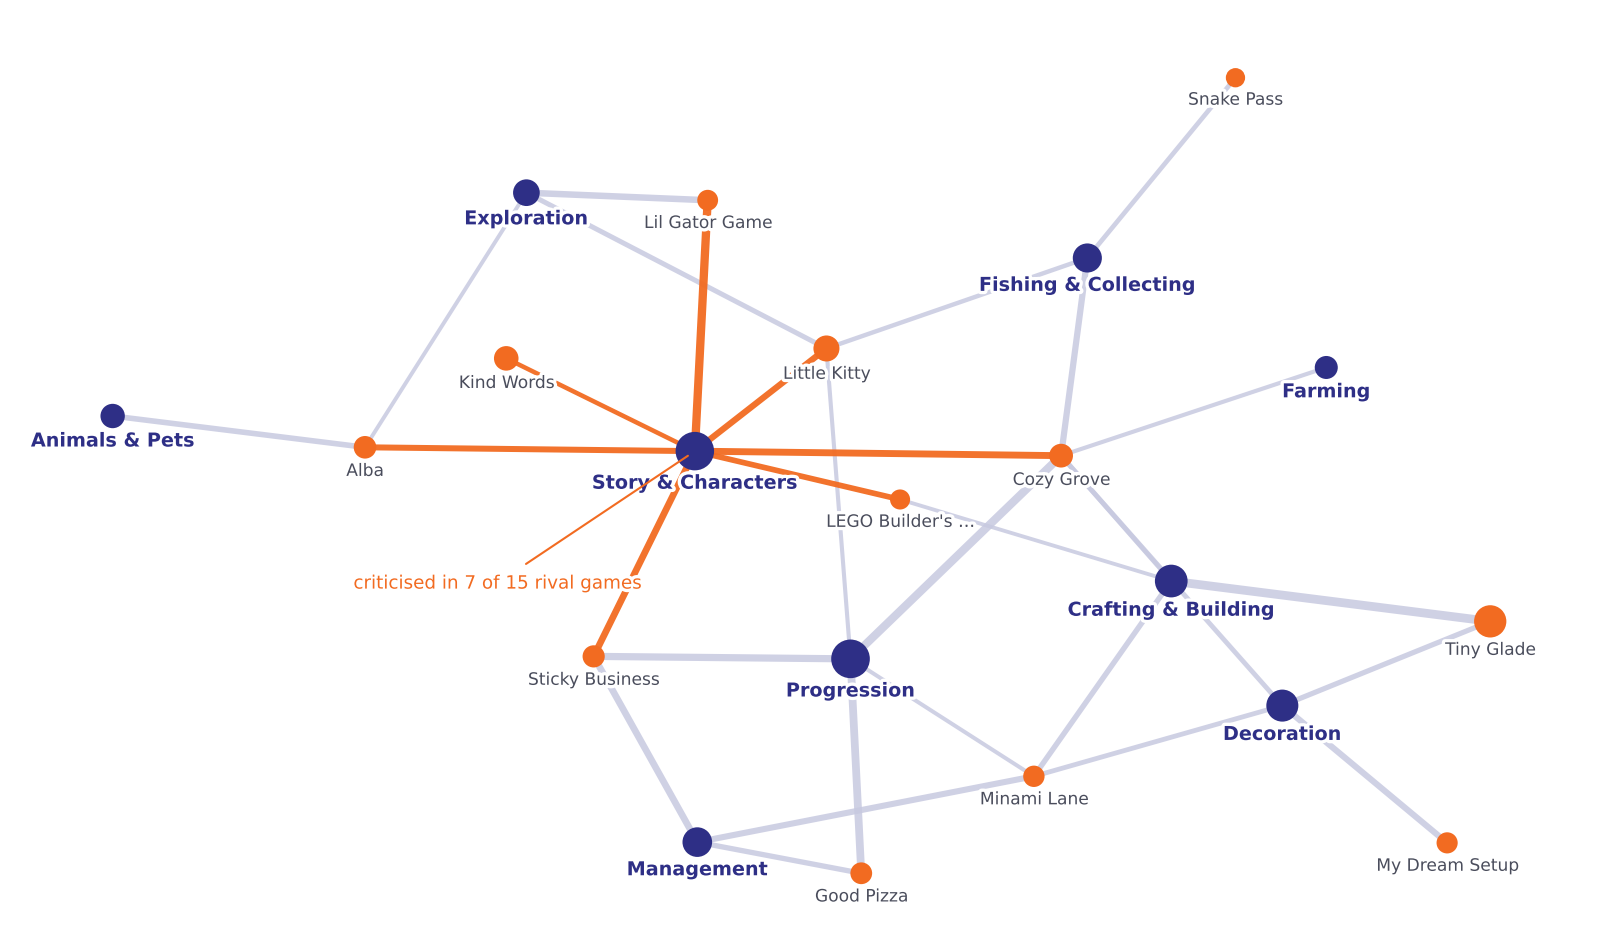

In [13]:
import matplotlib.patheffects as pe
from matplotlib import font_manager
plt.rcParams["font.family"] = "Inter" if "Inter" in {f.name for f in font_manager.fontManager.ttflist} else "DejaVu Sans"
W, HGT, NG = 5.2, 3.0, len(GAMES)
w = T_.loc[WIN]
def short(n):
    n = re.split(r" - | \(|: |,", n)[0]
    return n if len(n) <= 16 else n[:15] + "…"

H = nx.Graph()
for (g, t), d in LINKS.items():
    H.add_node(g, kind="game"); H.add_node(t, kind="topic")
    H.add_edge(g, t, share=d["share"])

pos = nx.kamada_kawai_layout(H, weight=None)
P = np.array([pos[k] for k in H]); P = (P - P.min(0)) / np.ptp(P, 0)
P[:, 0] *= W / HGT
for _ in range(800):
    moved = False
    for i in range(len(P)):
        for j in range(i + 1, len(P)):
            d = P[j] - P[i]; dist = np.hypot(*d)
            if dist < 0.21:
                push = d / (dist + 1e-9) * (0.21 - dist) / 2; P[i] -= push; P[j] += push; moved = True
    if not moved: break
pos = {k: tuple(v) for k, v in zip(H, P)}

ORANGE, NAVY, LINE, INK2 = "#f26b21", "#2e2f86", "#c7c9e0", "#4a4d5c"
vol = T_.reviews.to_dict(); pop = games.set_index("game").reviews.to_dict()
size = {v: (14 + 46 * pop[v] / max(pop.values())) if H.nodes[v]["kind"] == "game"
        else (16 + 70 * vol[v] / max(vol.values())) for v in H}
smax = max(d["share"] for d in LINKS.values())

fig, ax = plt.subplots(figsize=(W, HGT), dpi=300)
for u, v, d in H.edges(data=True):
    hot = WIN in (u, v)
    ax.plot(*zip(pos[u], pos[v]), color=ORANGE if hot else LINE, lw=(0.5 + 1.6 * d["share"] / smax),
            alpha=0.95 if hot else 0.85, zorder=2 if hot else 1, solid_capstyle="round")
for v in H:
    ax.scatter(*pos[v], s=size[v], color=NAVY if H.nodes[v]["kind"] == "topic" else ORANGE,
               edgecolors="none", zorder=3)
halo = [pe.withStroke(linewidth=1.6, foreground="white")]
for v, (x, y) in pos.items():
    is_t = H.nodes[v]["kind"] == "topic"
    ax.annotate(v if is_t else short(v), (x, y), xytext=(0, -(size[v] ** 0.5) / 2 - 0.8), textcoords="offset points",
                ha="center", va="top", fontsize=4.6 if is_t else 4.1, fontweight="bold" if is_t else "normal",
                color=NAVY if is_t else INK2, path_effects=halo, zorder=4)

# one orange note, like Sample C: placed in the emptiest spot near the winner
pts = np.array(list(pos.values()) + [tuple(np.array(pos[a]) * f + np.array(pos[b]) * (1 - f))
                                     for a, b in H.edges() for f in (0.25, 0.5, 0.75)])
x, y = pos[WIN]; best, bd = None, -1
for a in np.linspace(0, 2 * np.pi, 32, endpoint=False):
    for r in (0.18, 0.24, 0.30):
        tx, ty = x + r * np.cos(a), y + r * np.sin(a)
        if not (P[:, 0].min() <= tx <= P[:, 0].max() and P[:, 1].min() <= ty <= P[:, 1].max() + 0.05): continue
        dd = np.min(np.hypot(pts[:, 0] - tx, pts[:, 1] - ty))
        if dd > bd: best, bd = (tx, ty), dd
ax.annotate(f"criticised in {int(w.games)} of {NG} rival games", (x, y), xytext=best, textcoords="data",
            ha="center", va="center", fontsize=4.4, color=ORANGE, path_effects=halo, zorder=5,
            arrowprops=dict(arrowstyle="-", color=ORANGE, lw=0.5, shrinkA=1, shrinkB=2))

ax.margins(0.06); ax.axis("off"); ax.set_aspect("equal")
fig.tight_layout(pad=0.05)
fig.savefig(f"{OUT}/fig.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 9 · Save the results
Every number in the A4 report comes from `outputs/stats.json`. In Colab, the `outputs/` folder is also downloaded to your computer as `outputs.zip` when this cell finishes.

In [ ]:
def trow(r):
    return dict(topic=r.topic, games=int(r.games), reviews=int(r.reviews), biggest_game=r.biggest_game,
                biggest_share=float(r.biggest_share), linked_games=r.linked_games)

stats = dict(
    run_date=RUN_DATE, period=PERIOD,
    data=dict(steamspy_list=len(listing), games=len(GAMES), reviews=len(reviews), by_language=BY_LANG, game_list=GAMES),
    generic={t: round(share_all[t], 3) for t in GENERIC},
    params=dict(link_share=LINK_SHARE, min_reviews_per_link=MIN_REVIEWS_PER_LINK, n_per_lang=N_PER_LANG, langs=LANGS),
    graph=dict(nodes=H.number_of_nodes(), game_nodes=sum(v in GAMES for v in H),
               topic_nodes=sum(v in TOPICS for v in H), edges=H.number_of_edges()),
    winner=trow(TT[TT.topic == WIN].iloc[0]), backup=trow(TT[TT.topic == BACKUP].iloc[0]),
    loudest=trow(TT[TT.topic == loud.topic].iloc[0]),
    topics=[trow(r) for r in TT.sort_values(["games", "reviews"], ascending=False).itertuples()],
    alternatives=dict(generic_kept_winner=WIN_gen, npmi_winner=WIN_np, winner_lines_under_npmi=win_np_links),
    robustness=dict(sweep_hold=HOLD, sweep_total=len(sweep), loo_hold=LOO, loo_total=len(GAMES),
                    bootstrap=round(BOOT, 3), n_boot=N_BOOT, bootstrap_winners=dict(boot.most_common()),
                    sweep=sweep.to_dict("records")),
    decision=DECISION,
)
json.dump(stats, open(f"{OUT}/stats.json", "w"), indent=2, ensure_ascii=False, default=str)
TT.to_csv(f"{OUT}/topic_table.csv", index=False)
games.to_csv(f"{OUT}/games.csv", index=False)
pd.DataFrame([dict(game=g, topic=t, **d) for (g, t), d in LINKS.items()]).to_csv(f"{OUT}/edges.csv", index=False)
print(json.dumps({k: stats[k] for k in ["data", "graph", "decision"]}, indent=1, ensure_ascii=False, default=str))
print("saved →", sorted(os.listdir(OUT)))

shutil.make_archive("outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("outputs.zip")
except ImportError:
    print("not running in Colab — results are in", os.path.abspath(OUT))

{
 "data": {
  "steamspy_list": 779,
  "games": 15,
  "reviews": 3407,
  "by_language": {
   "english": 3400,
   "thai": 7
  },
  "game_list": [
   "Tiny Glade",
   "A Little to the Left",
   "Little Kitty, Big City",
   "Kind Words (lo fi chill beats to write to)",
   "Cozy Grove",
   "Melatonin",
   "Alba: A Wildlife Adventure",
   "Sticky Business",
   "Good Pizza, Great Pizza - Cooking Simulator Game",
   "Minami Lane",
   "My Dream Setup",
   "Lil Gator Game",
   "Cats Organized Neatly",
   "LEGO Builder's Journey",
   "Snake Pass"
  ]
 },
 "graph": {
  "nodes": 21,
  "game_nodes": 12,
  "topic_nodes": 9,
  "edges": 31
 },
 "decision": "turn Story & Characters into our strength"
}
saved → ['audit_sample.csv', 'edges.csv', 'fig.png', 'games.csv', 'robustness_sweep.csv', 'stats.json', 'topic_table.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>